# Small biomedical transformers: how much model do you need?

**Module 04.1 · my implementation**, Seid Adem

> **The question in plain language.** The course fine-tuned **PubMedBERT** (110 million parameters) to label the
> sentences of medical abstracts (background / objective / methods / results / conclusions). Bigger models usually
> read text better, but they cost more: slower training, slower predictions, more memory, more energy. In a real
> project (say, labelling millions of abstracts on a modest server) that trade-off decides which model you ship.
> ([Transformers and fine-tuning explained in Lessons 4–6](../LESSONS.md))

This notebook fine-tunes **four biomedical transformers of very different sizes** with the same hand-written PyTorch
loop, the same 400 training abstracts and the same official test set (29,578 sentences) as
[notebook 01](01_pytorch_mlp_pubmed_rct.ipynb), and measures **accuracy, training time and prediction speed**.

| Model | What it is |
|---|---|
| `nlpie/tiny-biobert` | a 4-layer "distilled" student of BioBERT (a small model trained to imitate a big one) |
| `nlpie/bio-mobilebert` | MobileBERT (designed for phones), further trained on biomedical text |
| `nlpie/distil-biobert` | a 6-layer distilled BioBERT |
| `microsoft/BiomedNLP-PubMedBERT-…` | the course's model: 12 layers, trained from scratch on PubMed |

In [1]:
import json
import time
import warnings
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import transformers
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

from dsls.textclf import pick_device

warnings.filterwarnings("ignore", category=FutureWarning)
datasets.utils.logging.set_verbosity_error()
transformers.logging.set_verbosity_error()  # hide "some weights were newly initialised" (expected: the new head)
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 0
LABELS = ["background", "objective", "methods", "results", "conclusions"]
DEVICE = pick_device()
CHECKPOINTS = {
    "tiny-biobert": "nlpie/tiny-biobert",
    "bio-mobilebert": "nlpie/bio-mobilebert",
    "distil-biobert": "nlpie/distil-biobert",
    "PubMedBERT": "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext",
}
print("device:", DEVICE, "| torch", torch.__version__, "| transformers", transformers.__version__)

ds = load_dataset("armanc/pubmed-rct20k")
train, val, test = (ds[s].to_pandas() for s in ("train", "validation", "test"))
for df in (train, val, test):
    df["n_sentences"] = df.groupby("abstract_id")["sentence_id"].transform("max") + 1
    df["y"] = df["label"].map(LABELS.index)
small = train[
    train["abstract_id"].isin(train["abstract_id"].unique()[:400])
].copy()  # same 400 abstracts as notebook 01
val_small = val[
    val["abstract_id"].isin(val["abstract_id"].unique()[:200])
].copy()  # for choosing the best epoch
print(f"training {len(small):,} sentences | validation {len(val_small):,} | test {len(test):,}")

device: mps | torch 2.15.0 | transformers 4.57.6
training 4,732 sentences | validation 2,371 | test 29,578


## 1 · Tokenizers: how each model chops up text

> **In plain language.** A transformer never sees words. A **tokenizer** first splits text into pieces from a fixed
> vocabulary (about 30,000 entries). Common words stay whole; rare words are split into fragments marked `##`. A model
> whose vocabulary was built from biomedical text keeps drug and gene names whole, so each name is *one* thing the
> model learned about, not a jumble of fragments. More pieces also mean longer inputs, and transformers slow down
> with length.

In [2]:
sentence = "Patients with EGFR-mutant lung cancer received gefitinib or carboplatin-paclitaxel."
tokenizers = {name: AutoTokenizer.from_pretrained(ckpt) for name, ckpt in CHECKPOINTS.items()}
for name, tok in tokenizers.items():
    pieces = tok.tokenize(sentence)
    print(f"{name:15s} vocabulary {tok.vocab_size:6,} | {len(pieces):2d} pieces: {' '.join(pieces)}")

lengths = {name: np.mean([len(ids) for ids in tok(test["text"].tolist())["input_ids"]])
           for name, tok in tokenizers.items()}  # fmt: skip
print("\naverage tokens per test sentence:", {k: round(v, 1) for k, v in lengths.items()})

tiny-biobert    vocabulary 28,996 | 30 pieces: Pat ##ients with E ##G ##F ##R - mutant lung cancer received g ##ef ##iti ##ni ##b or car ##bo ##p ##lat ##in - p ##ac ##lit ##ax ##el .
bio-mobilebert  vocabulary 30,522 | 25 pieces: patients with e ##gf ##r - mutant lung cancer received ge ##fi ##tin ##ib or car ##bo ##pl ##atin - pac ##lita ##x ##el .
distil-biobert  vocabulary 28,996 | 30 pieces: Pat ##ients with E ##G ##F ##R - mutant lung cancer received g ##ef ##iti ##ni ##b or car ##bo ##p ##lat ##in - p ##ac ##lit ##ax ##el .
PubMedBERT      vocabulary 30,522 | 14 pieces: patients with egfr - mutant lung cancer received gefitinib or carboplatin - paclitaxel .



average tokens per test sentence: {'tiny-biobert': np.float64(37.3), 'bio-mobilebert': np.float64(35.7), 'distil-biobert': np.float64(37.3), 'PubMedBERT': np.float64(32.3)}


**Vocabulary decides how a model "sees" biomedical words.** PubMedBERT's vocabulary was built from PubMed text, so
*egfr*, *gefitinib*, *carboplatin* and *paclitaxel* are each **one** piece: 14 pieces for the whole sentence. The
BioBERT family reuses the original BERT vocabulary, built from Wikipedia and books, and continued training on
biomedical text. It shreds the same sentence into 30 pieces (`g ##ef ##iti ##ni ##b`). That model has to rebuild
the meaning of "gefitinib" from five fragments every time.

Across the test set PubMedBERT needs 32 tokens per sentence on average, against 36–37 for the others: about 13 %
shorter inputs, which also means less computation per sentence.

> **In plain language.** Continuing to train a general model on biomedical text teaches it new *facts*, but not new
> *words*: the vocabulary is fixed at the start. Building the vocabulary from the domain itself is one reason
> PubMedBERT does well on biomedical tasks.

## 2 · Fine-tuning, written out by hand

> **In plain language.** **Fine-tuning** takes a model that already "reads" biomedical English (from pre-training on
> millions of abstracts) and adds a small new output layer with one score per class. Then *all* weights are trained a
> little on our labelled sentences. Three details matter:
> * a **small learning rate** (the step size), so the pre-trained knowledge is adjusted, not overwritten;
> * **warm-up**: the learning rate ramps up from zero over the first 10 % of steps, then decays linearly to zero.
>   Big early steps on a randomly initialised output layer can damage the pre-trained weights;
> * **checkpoint selection**: after each epoch (one pass over the training data), score the validation set and keep
>   the best epoch's weights, the same idea as early stopping in notebook 01.

The course used Hugging Face's `Trainer`, which hides this loop. Here it is in full (about 40 lines):

In [3]:
def batches(texts, size):
    # Sort by length so each batch pads to similar lengths (much faster), but remember the original order.
    order = np.argsort([len(t) for t in texts])
    for start in range(0, len(order), size):
        yield order[start : start + size]


@torch.no_grad()
def predict(model, tok, texts, batch_size=128, max_length=128):
    model.eval()
    preds = np.empty(len(texts), dtype=int)
    for idx in batches(texts, batch_size):
        enc = tok(
            [texts[i] for i in idx], truncation=True, max_length=max_length, padding=True, return_tensors="pt"
        )
        preds[idx] = model(**enc.to(DEVICE)).logits.argmax(-1).cpu().numpy()
    return preds


def fine_tune(checkpoint, train_df, val_df, text="text", epochs=3, lr=5e-5, batch_size=16, max_length=128):
    torch.manual_seed(SEED)
    tok = AutoTokenizer.from_pretrained(checkpoint)
    model = AutoModelForSequenceClassification.from_pretrained(checkpoint, num_labels=len(LABELS)).to(DEVICE)
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    steps_per_epoch = -(-len(train_df) // batch_size)
    schedule = get_linear_schedule_with_warmup(
        optimiser, int(0.1 * epochs * steps_per_epoch), epochs * steps_per_epoch
    )
    texts, labels = train_df[text].tolist(), torch.tensor(train_df["y"].values)
    rng = np.random.default_rng(SEED)
    history, best_f1, best_state, start = [], -1.0, None, time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        for idx in np.array_split(rng.permutation(len(texts)), steps_per_epoch):
            enc = tok(
                [texts[i] for i in idx],
                truncation=True,
                max_length=max_length,
                padding=True,
                return_tensors="pt",
            )
            loss = model(**enc.to(DEVICE), labels=labels[idx].to(DEVICE)).loss
            loss.backward()
            optimiser.step()
            schedule.step()
            optimiser.zero_grad()
        val_f1 = f1_score(val_df["y"], predict(model, tok, val_df[text].tolist()), average="macro")
        history.append({"epoch": epoch, "val_macro_f1": val_f1, "last_batch_loss": loss.item()})
        if val_f1 > best_f1:
            best_f1, best_state = val_f1, {k: v.detach().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, tok, history, time.perf_counter() - start

One setting for every model: **3 epochs, learning rate 5 × 10⁻⁵, batch size 16, 10 % warm-up**. That is a common
default, not tuned per model. The course used 2 × 10⁻⁵, which is often too gentle for small models in only three
epochs. Training and prediction times include tokenization and are measured on this laptop's GPU.

In [4]:
def evaluate(name, model, tok, seconds, text="text", variant="sentence only"):
    start = time.perf_counter()
    pred = predict(model, tok, test[text].tolist())
    infer = time.perf_counter() - start
    return {"model": name, "input": variant, "parameters (M)": sum(p.numel() for p in model.parameters()) / 1e6,
            "accuracy": accuracy_score(test["y"], pred), "macro-F1": f1_score(test["y"], pred, average="macro"),
            "training seconds": seconds, "test sentences / s": len(test) / infer}  # fmt: skip


results, histories = [], {}
for name, ckpt in CHECKPOINTS.items():
    model, tok, history, seconds = fine_tune(ckpt, small, val_small)
    histories[name] = history
    results.append(evaluate(name, model, tok, seconds))
    print(f"{name:15s} best epoch {max(history, key=lambda h: h['val_macro_f1'])['epoch']} | "
          f"test macro-F1 {results[-1]['macro-F1']:.3f} | trained in {seconds:.0f} s")  # fmt: skip
    del model
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
pd.DataFrame(results).round(3)

tiny-biobert    best epoch 3 | test macro-F1 0.750 | trained in 50 s


bio-mobilebert  best epoch 3 | test macro-F1 0.153 | trained in 245 s


distil-biobert  best epoch 3 | test macro-F1 0.774 | trained in 178 s


PubMedBERT      best epoch 3 | test macro-F1 0.795 | trained in 310 s


,model,input,parameters (M),accuracy,macro-F1,training seconds,test sentences / s
0,tiny-biobert,sentence only,13.876,0.817,0.750,49.929,1583.397
1,bio-mobilebert,sentence only,24.584,0.295,0.153,244.921,237.754
2,distil-biobert,sentence only,65.787,0.838,0.774,177.941,408.096
3,PubMedBERT,sentence only,109.486,0.858,0.795,309.649,225.462


**Three of the four models learned the task; size bought accuracy, at a price.**

| | tiny-biobert | distil-biobert | PubMedBERT |
|---|---|---|---|
| parameters | 14 M | 66 M | 109 M |
| test macro-F1 | 0.750 | 0.774 | **0.795** |
| training time | **50 s** | 178 s | 310 s |
| test sentences per second | **1,583** | 408 | 225 |

* **tiny-biobert** is 8× smaller than PubMedBERT, trains 6× faster and predicts 7× faster, for 0.045 less macro-F1.
  Labelling 10 million abstracts' worth of sentences would take hours instead of days.
* **PubMedBERT fine-tuned with my loop scores 0.795**, slightly above the course's own run on the same test set
  (0.782, notebook 01) with a similar amount of data. It trained in **about 5 minutes** on this laptop.
* **bio-mobilebert failed**: macro-F1 0.153, close to always guessing one class. That needs explaining before
  anything else is concluded.

*Timing caveat: other software was using the laptop's GPU during some of these runs, so treat the times as
approximate, and compare their ratios rather than the exact seconds.*

In [5]:
# Why did bio-mobilebert fail? Look at the brand-new output layer's scores *before* any training.
two = [
    "Patients were randomly assigned to receive gefitinib or placebo.",
    "Mortality was lower in the treated group.",
]
for name in ("tiny-biobert", "bio-mobilebert"):
    torch.manual_seed(SEED)
    fresh = AutoModelForSequenceClassification.from_pretrained(
        CHECKPOINTS[name], num_labels=len(LABELS)
    ).eval()
    with torch.no_grad():
        logits = fresh(**tokenizers[name](two, return_tensors="pt", padding=True)).logits
    print(f"{name:15s} initial class scores:", np.round(logits.numpy(), 1).tolist())

tiny-biobert    initial class scores: [[0.10000000149011612, -0.10000000149011612, 0.10000000149011612, 0.0, -0.0], [0.10000000149011612, -0.10000000149011612, 0.10000000149011612, 0.0, -0.0]]


bio-mobilebert  initial class scores: [[-53752.69921875, 19206.80078125, 32231.5, -1718.699951171875, 125.69999694824219], [-48862.19921875, 17492.19921875, 29269.19921875, -1588.5999755859375, 156.89999389648438]]


**The diagnosis.** tiny-biobert's new output layer starts with scores around ±0.1: undecided, as it should be.
bio-mobilebert's starts with scores in the **tens of thousands**, nearly identical for two very different
sentences. MobileBERT was designed for phones and replaces the usual normalisation layers (which keep numbers in a
sensible range) with a cheaper operation, so its internal values reach about 200,000. The new classification layer
receives those huge numbers directly. The model is "certain" of one class from step one, and three epochs of gentle
updates can't pull it out.

I checked the obvious remedies in a side experiment with the same loop (not repeated here, to save 15 minutes):

* **The pre-trained model itself is fine.** It correctly fills in "Patients were randomly [MASK] to receive…" with
  *assigned / allocated / selected*, identically on the CPU and the GPU.
* **Changing the learning rate didn't help** (2 × 10⁻⁵, 5 × 10⁻⁵ and 10⁻⁴ all stayed at validation macro-F1 ≈ 0.16).
* **Normalising the vector before the output layer (LayerNorm) didn't help either** (0.10).

Making MobileBERT work would need model-specific handling (published recipes use different pooling, more epochs and
careful tuning). That is outside this comparison, so it is reported as a failure, not quietly dropped.

> **In plain language.** "Same recipe for every model" is fair, but a recipe can suit one architecture and break
> another. When a model scores near chance, **look inside before blaming the data or the model's quality**: here,
> one line printing the initial outputs revealed the problem.

## 3 · Adding the position, as text

Notebook 01's most valuable feature was **where the sentence sits in its abstract**: it lifted a small MLP's macro-F1
from 0.671 to 0.797. A transformer only reads text, so the simplest way to give it that information is to **write it
into the input**: `"sentence 3 of 12: <the sentence>"`.

> **In plain language.** This is a general trick: if a model only accepts text, extra facts can be phrased as text.
> The model has to *learn* what "3 of 12" means from the training examples, but numbers like these appear constantly
> in its pre-training data.

In [6]:
for df in (small, val_small, test):
    df["text_pos"] = (
        "sentence "
        + (df["sentence_id"] + 1).astype(str)
        + " of "
        + df["n_sentences"].astype(str)
        + ": "
        + df["text"]
    )
print(test["text_pos"].iloc[3])

for name in ("distil-biobert", "PubMedBERT"):
    model, tok, history, seconds = fine_tune(CHECKPOINTS[name], small, val_small, text="text_pos")
    results.append(evaluate(name, model, tok, seconds, text="text_pos", variant="sentence + position"))
    print(f"{name:15s} + position: test macro-F1 {results[-1]['macro-F1']:.3f} | trained in {seconds:.0f} s")
    del model
    if DEVICE.type == "mps":
        torch.mps.empty_cache()

table = pd.DataFrame(results)
Path("results").mkdir(exist_ok=True)
table.round(4).to_csv("results/02_small_transformers.csv", index=False)
table.round(3)

sentence 4 of 9: Survival analyses were used to assess the association between admission Model of End-Stage Liver Disease Excluding International Normalized Ratio ( MELD-XI ) scores and patient outcome.There was a high prevalence of abnormal baseline ( admission ) LFTs ( albumin @ % , aspartate transaminase @ % , alanine transaminase @ % , and total bilirubin @ % ) .


distil-biobert  + position: test macro-F1 0.834 | trained in 185 s


PubMedBERT      + position: test macro-F1 0.847 | trained in 325 s


,model,input,parameters (M),accuracy,macro-F1,training seconds,test sentences / s
0,tiny-biobert,sentence only,13.876,0.817,0.750,49.929,1583.397
1,bio-mobilebert,sentence only,24.584,0.295,0.153,244.921,237.754
2,distil-biobert,sentence only,65.787,0.838,0.774,177.941,408.096
3,PubMedBERT,sentence only,109.486,0.858,0.795,309.649,225.462
4,distil-biobert,sentence + position,65.787,0.886,0.834,185.225,377.567
5,PubMedBERT,sentence + position,109.486,0.899,0.847,325.253,206.351


**Writing the position into the text works, and makes the transformers the best models in this module.**

| Model (400 training abstracts) | sentence only | + position | gain |
|---|---|---|---|
| MLP on TF-IDF (notebook 01) | 0.671 | 0.797 | +0.126 |
| distil-biobert | 0.774 | 0.834 | +0.060 |
| PubMedBERT | 0.795 | **0.847** | +0.052 |

PubMedBERT with the position reaches **macro-F1 0.847 (accuracy 0.899)** from 400 abstracts. That beats notebook
01's MLP + position trained on **all 15,000** abstracts (0.833). Two lessons:

* **Pre-training is worth a lot of labelled data.** A model that already reads biomedical English needs far fewer
  labelled examples.
* **The position helps transformers less than the MLP** (+0.05 vs +0.13): a transformer reading *"We aimed to…"*
  already guesses "objective" from the wording. But it still helps, because wording alone can't settle cases such as
  background vs objective.

Adding 16 characters of text cost almost nothing (about 5 % more training time) and was worth more than doubling the
model size.

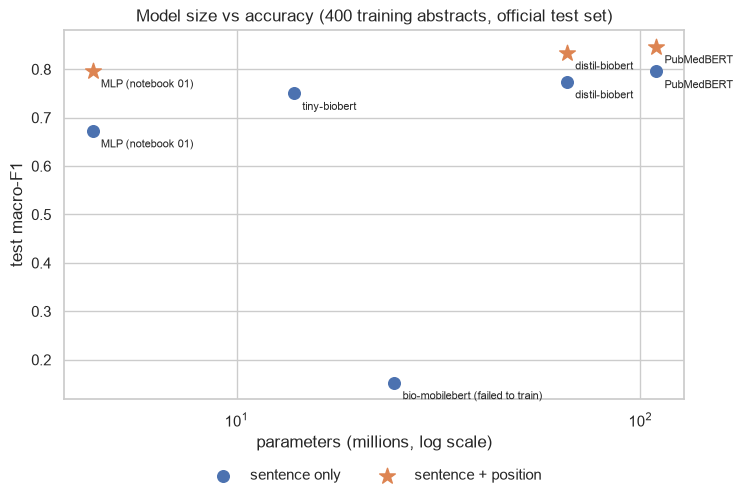

In [7]:
mlp = pd.DataFrame(
    [  # notebook 01, same 400 training abstracts, same test set
        {"model": "MLP (notebook 01)", "input": "sentence only", "parameters (M)": 4.4, "macro-F1": 0.671},
        {
            "model": "MLP (notebook 01)",
            "input": "sentence + position",
            "parameters (M)": 4.4,
            "macro-F1": 0.797,
        },
    ]
)
plot = pd.concat([table, mlp], ignore_index=True)
fig, ax = plt.subplots(figsize=(8, 4.8))
for variant, marker in (("sentence only", "o"), ("sentence + position", "*")):
    part = plot[plot["input"] == variant]
    ax.scatter(
        part["parameters (M)"], part["macro-F1"], s=140 if marker == "*" else 70, marker=marker, label=variant
    )
    for _, r in part.iterrows():
        label = r["model"] + (" (failed to train)" if r["macro-F1"] < 0.3 else "")
        ax.annotate(
            label,
            (r["parameters (M)"], r["macro-F1"]),
            textcoords="offset points",
            xytext=(6, -12),
            fontsize=8,
        )
ax.set_xscale("log")
ax.set(xlabel="parameters (millions, log scale)", ylabel="test macro-F1",
       title="Model size vs accuracy (400 training abstracts, official test set)")  # fmt: skip
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.savefig(FIGURES / "04_size_vs_accuracy.png", dpi=150, bbox_inches="tight")
plt.show()

## 4 · Why did the course's run take 3 h 15 min?

> **In plain language.** Training time depends on the hardware *and* on everything else the computer is doing. Before
> blaming the model, read the log. Hugging Face's `Trainer` saves one (`trainer_state.json`) next to each checkpoint.

In [8]:
state_file = Path(
    "../course_materials/local/runnable/artifacts/session1B_transformer/checkpoint-1800/trainer_state.json"
)
if state_file.exists():
    log = pd.DataFrame([h for h in json.loads(state_file.read_text())["log_history"] if "eval_runtime" in h])
    print(log[["epoch", "eval_runtime", "eval_samples_per_second", "eval_f1_macro"]].to_string(index=False))
else:
    print(
        "course run not found locally (run the course notebook 1B via `make runnable` to reproduce this check)"
    )

 epoch  eval_runtime  eval_samples_per_second  eval_f1_macro
   1.0        9.5227                  168.020       0.802327
   2.0     2107.1128                    0.759       0.790661
   3.0        9.4229                  169.799       0.815225


**The course run wasn't slow because of the model.** Its first and third evaluations (1,600 sentences) took
**9.5 seconds**, or 170 sentences per second, normal speed for this GPU. The second took **2,107 seconds (35
minutes)** for the identical work. Something outside the code paused the run: the laptop sleeping, or other heavy
programs. The checkpoint timestamps (22:55 → 00:04 → 01:59) show the same uneven pace. My hand-written loop trained
the same model on similar data in about 5 minutes.

> **In plain language.** Before concluding "this model takes 3 hours", read the logs. Long runs on a laptop are
> fragile: keep it awake (on macOS, `caffeinate -i`), close heavy programs, and log time per epoch, as both my
> loops do.

## Conclusions

1. **Fine-tuning is a short loop, not magic:** load a pre-trained model, add an output layer, train everything with
   a small learning rate, warm-up and checkpoint selection. About 40 lines replace `Trainer`.
2. **Small models are often enough:** tiny-biobert (14 M parameters) got within 0.05 macro-F1 of PubMedBERT at an
   eighth of the cost. Measure the trade-off before defaulting to the biggest model.
3. **Vocabulary matters for domain text:** PubMedBERT keeps drug and gene names whole, while the BioBERT family
   splits them into fragments.
4. **Facts can be given to a text model as text:** "sentence 3 of 12:" raised PubMedBERT from 0.795 to **0.847**,
   the best result in this module, from 400 training abstracts.
5. **Diagnose failures:** bio-mobilebert's near-chance score came from huge initial outputs, which one printed line
   revealed. It is reported, not dropped.
6. **Read the logs before blaming the model:** the course's 3 h 15 min run contained a single 35-minute stall;
   the model itself trains in minutes.

*Runtime: about 30 minutes on an Apple-silicon laptop (GPU via MPS). Models are downloaded from the Hugging Face hub
(nlpie models: MIT licence; PubMedBERT: MIT licence) into the local cache, never committed.
Results table: [`results/02_small_transformers.csv`](results/02_small_transformers.csv).*